<a href="https://colab.research.google.com/github/Jhonny12345678-stack/Reinforcement-Learning-Q-Learning/blob/main/Reinforcement_Learning_Q_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

S14 - Reinforcement Learning

Andrés Camilo Patiño Serna
Jhonattan Pineda Cardona
Yansit Stiven Rodriguez Díaz

In [1]:

import numpy as np
import matplotlib.pyplot as plt

print("Librerías importadas correctamente.")


Librerías importadas correctamente.


Construir el laberinto:

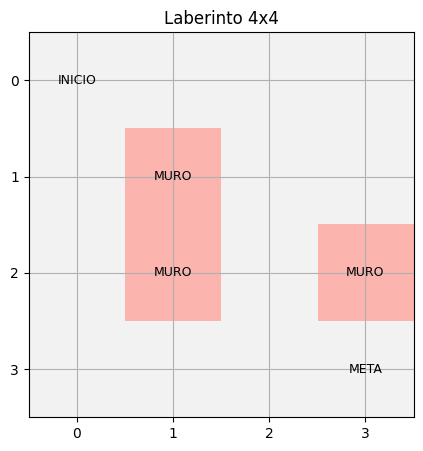

In [2]:

# Crear el laberinto de 4x4
laberinto = np.zeros((4, 4))

# Definir los obstáculos
obstaculos = [(1, 1), (2, 1), (2, 3)]

for fila, columna in obstaculos:
    laberinto[fila, columna] = -1

# Definir inicio y meta
inicio = (0, 0)
meta = (3, 3)

# Representar el laberinto
plt.figure(figsize=(5, 5))
plt.imshow(laberinto, cmap="Pastel1")

for fila in range(4):
    for columna in range(4):
        if (fila, columna) == inicio:
            texto = "INICIO"
        elif (fila, columna) == meta:
            texto = "META"
        elif (fila, columna) in obstaculos:
            texto = "MURO"
        else:
            texto = ""

        plt.text(columna, fila, texto,
                 ha="center", va="center", fontsize=9)

plt.xticks(range(4))
plt.yticks(range(4))
plt.grid()
plt.title("Laberinto 4x4")
plt.show()


Crear las acciones y recompensas:

In [3]:

# Definir las acciones del agente
acciones = {
    0: (-1, 0),  # Arriba
    1: (1, 0),   # Abajo
    2: (0, -1),  # Izquierda
    3: (0, 1)    # Derecha
}

# Definir las recompensas
recompensa_meta = 10
recompensa_muro = -5
recompensa_movimiento = -1

print("Acciones y recompensas definidas correctamente.")


Acciones y recompensas definidas correctamente.


Crear la tabla Q: La tabla Q permitirá que el agente aprenda qué acciones son mejores según la posición en la que se encuentre.

In [4]:

# Crear la tabla Q
Q = np.zeros((16, 4))

# Definir parámetros de aprendizaje
tasa_aprendizaje = 0.1
factor_descuento = 0.9
exploracion = 0.2

print("Tabla Q creada correctamente.")
print("Dimensiones de la tabla:", Q.shape)
print(Q)


Tabla Q creada correctamente.
Dimensiones de la tabla: (16, 4)
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


Implementar el algoritmo Q - Learning : Es el aprendizaje por refuerzo, tendrá dos funciones, una para convertir la posición del agente en un estado , otra para ejecutar los movimientos dentro del laberinto y asignar las recompensas.


In [5]:

# Convertir una posición en un estado
def obtener_estado(posicion):
    return posicion[0] * 4 + posicion[1]


# Ejecutar una acción
def mover_agente(posicion, accion):
    movimiento = acciones[accion]

    nueva_fila = posicion[0] + movimiento[0]
    nueva_columna = posicion[1] + movimiento[1]

    # Verificar límites del laberinto
    if not (0 <= nueva_fila < 4 and 0 <= nueva_columna < 4):
        return posicion, recompensa_muro

    nueva_posicion = (nueva_fila, nueva_columna)

    # Verificar obstáculos
    if nueva_posicion in obstaculos:
        return posicion, recompensa_muro

    # Verificar llegada a la meta
    if nueva_posicion == meta:
        return nueva_posicion, recompensa_meta

    return nueva_posicion, recompensa_movimiento


print("Funciones del agente creadas correctamente.")


Funciones del agente creadas correctamente.


Entrenar el agente con Q-Learning: En esta etapa, el agente realizará múltiples intentos para aprender a encontrar la salida.

Se utilizarán:
- 500 episodios: intentos de aprendizaje.
- Tasa de aprendizaje: 0.1.
- Factor de descuento: 0.9.
- Exploración: 0.2.

El agente está aprendiendo mediante prueba y error:

1. Selecciona un movimiento.
2. Recibe una recompensa o penalización.
3. Actualiza los valores de la tabla Q.
4. Repite el proceso hasta completar los 500 episodios.

In [6]:

# Entrenamiento del agente
episodios = 500
recompensas_totales = []

for episodio in range(episodios):

    posicion = inicio
    recompensa_episodio = 0

    for paso in range(100):

        estado = obtener_estado(posicion)

        # Elegir una acción
        if np.random.random() < exploracion:
            accion = np.random.randint(4)
        else:
            accion = np.argmax(Q[estado])

        # Ejecutar movimiento
        nueva_posicion, recompensa = mover_agente(posicion, accion)
        nuevo_estado = obtener_estado(nueva_posicion)

        # Actualizar tabla Q
        Q[estado, accion] += tasa_aprendizaje * (
            recompensa + factor_descuento * np.max(Q[nuevo_estado])
            - Q[estado, accion]
        )

        posicion = nueva_posicion
        recompensa_episodio += recompensa

        # Finalizar si encuentra la meta
        if posicion == meta:
            break

    recompensas_totales.append(recompensa_episodio)

print("Entrenamiento finalizado correctamente.")
print("Episodios ejecutados:", episodios)


Entrenamiento finalizado correctamente.
Episodios ejecutados: 500


Graficar los resultados del entrenamiento:

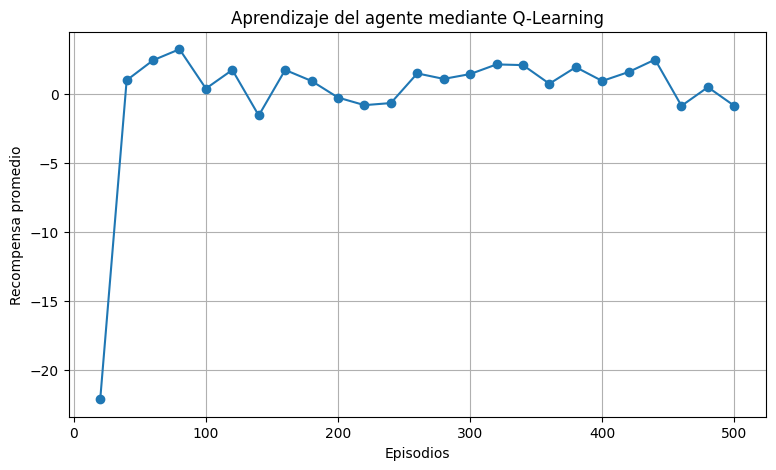

In [7]:

# Calcular el promedio de recompensas cada 20 episodios
promedios = [
    np.mean(recompensas_totales[i:i+20])
    for i in range(0, 500, 20)
]

# Graficar resultados
plt.figure(figsize=(9, 5))
plt.plot(range(20, 501, 20), promedios, marker="o")

plt.title("Aprendizaje del agente mediante Q-Learning")
plt.xlabel("Episodios")
plt.ylabel("Recompensa promedio")
plt.grid()
plt.show()


Comprobar si el agente aprendió a encontrar la salida:

In [8]:

# Probar el agente después del entrenamiento
posicion = inicio
recorrido = [posicion]

for paso in range(20):

    estado = obtener_estado(posicion)

    # Elegir la mejor acción aprendida
    accion = np.argmax(Q[estado])

    nueva_posicion, recompensa = mover_agente(posicion, accion)

    posicion = nueva_posicion
    recorrido.append(posicion)

    if posicion == meta:
        break

print("Recorrido del agente:", recorrido)

if posicion == meta:
    print("¡El agente encontró la salida!")
else:
    print("El agente no encontró la salida.")


Recorrido del agente: [(0, 0), (0, 1), (0, 2), (1, 2), (2, 2), (3, 2), (3, 3)]
¡El agente encontró la salida!


Visualizar el recorrido en el laberinto:

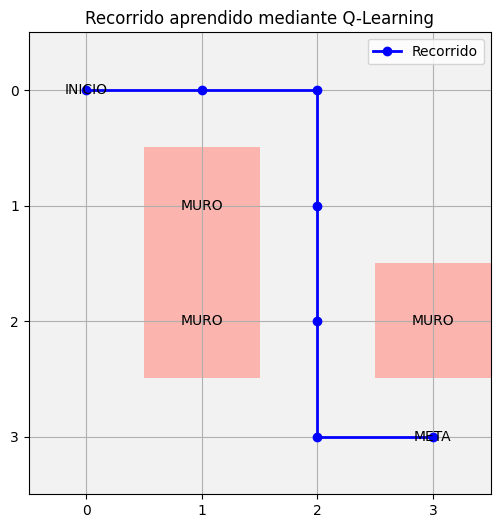

In [9]:

# Visualizar el recorrido aprendido
plt.figure(figsize=(6, 6))
plt.imshow(laberinto, cmap="Pastel1")

for fila in range(4):
    for columna in range(4):
        if (fila, columna) == inicio:
            texto = "INICIO"
        elif (fila, columna) == meta:
            texto = "META"
        elif (fila, columna) in obstaculos:
            texto = "MURO"
        else:
            texto = ""

        plt.text(columna, fila, texto,
                 ha="center", va="center")

# Dibujar el camino del agente
x = [p[1] for p in recorrido]
y = [p[0] for p in recorrido]

plt.plot(x, y, marker="o", linewidth=2,
         color="blue", label="Recorrido")

plt.xticks(range(4))
plt.yticks(range(4))
plt.grid()
plt.legend()
plt.title("Recorrido aprendido mediante Q-Learning")
plt.show()
